# TVmaze: does a synopsis improve rating classification?

**Bekzat Rashiduly · Machine Learning Algorithms · Final · November 2026**

Research question: does plot-description text improve prediction of **TVmaze rating ≥ 8/10**, given structured metadata?

This notebook is an executable walkthrough of the recorded experiment and the saved-model predictions. It loads the complete search results included with the project. It does **not** silently repeat the expensive exhaustive searches. To retrain every candidate in a new isolated directory, run `python code/run_final.py --fresh --workers 4`. The report documents contributions and tool use.

Data: [TVmaze API](https://www.tvmaze.com/api), CC BY-SA 4.0. Pretrained model: [all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), Apache-2.0.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import joblib
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'code/final_models.py').exists():
    raise RuntimeError('Open this notebook with the tvmaze_project directory as the working directory.')
sys.path.insert(0, str(ROOT / 'code'))
from endterm import check_continuity
from project import FEATURES
from final_models import teacher_grids
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import f1_score, confusion_matrix

OUT = ROOT / 'results/final'
summary = json.loads((OUT / 'analysis_summary.json').read_text())
_, train, test, folds, midterm, continuity = check_continuity(ROOT)
print('Verified raw response hashes:', continuity['raw_hashes_verified'])
display(pd.DataFrame([
    {'split': 'training', 'series': len(train), 'positive': int(train.high_rated.sum())},
    {'split': 'reused test benchmark', 'series': len(test), 'positive': int(test.high_rated.sum())}
]))

Verified raw response hashes: 60


,split,series,positive
0,training,1871,323
1,reused test benchmark,468,81


## 1. One series is one example

The collected snapshot contains 14,055 shows. Filtering to rated, English, scripted series leaves 2,339 examples. Unknown ratings cannot provide supervised labels. The seven metadata inputs describe the series; the synopsis is the additional text input. The rating creates the label and is excluded from the model features.

The saved 80/20 split and five outer training folds are the same as earlier course stages. The test set has been seen in earlier reports, so it is a **reused benchmark**, not a fresh prospective evaluation.

In [2]:
print('Metadata features:', FEATURES)
display(train[FEATURES + ['plot_summary']].head(3))
display(train.high_rated.value_counts().rename_axis('rating >= 8').to_frame('training examples'))
assert set(train.show_id).isdisjoint(set(test.show_id))
assert train.plot_summary.str.strip().ne('').all()
assert test.plot_summary.str.strip().ne('').all()

Metadata features: ['premiere_year', 'runtime_minutes', 'network', 'web_channel', 'broadcast_country', 'distribution', 'genres']


,premiere_year,runtime_minutes,network,web_channel,broadcast_country,distribution,genres,plot_summary
0,2013.0,60.0,CBS,None,US,Broadcast,"[""Drama"", ""Science-Fiction"", ""Thriller""]",Under the Dome is the story of a small town th...
1,2012.0,60.0,The CW,None,US,Broadcast,"[""Action"", ""Drama"", ""Science-Fiction""]","After a violent shipwreck, billionaire playboy..."
2,2014.0,60.0,The CW,None,US,Broadcast,"[""Action"", ""Adventure"", ""Science-Fiction""]","Ninety-seven years ago, nuclear Armageddon dec..."


,training examples
rating >= 8,
0,1548
1,323


## 2. Feature engineering and model selection

We add genre count, genre combinations, premiere decade and runtime buckets. Numeric missing values use training medians. A separate cross-fitted target-encoding experiment tests sparse categories. Each fitted preprocessing step stays inside the corresponding training fold.

An outer fold evaluates the entire inner tuning procedure: five outer folds, three inner folds. A separate five-fold search on the full training partition chooses the saved settings. Every Cartesian combination below is evaluated; there is no random search.

In [3]:
display(pd.DataFrame([
    {'family': family, 'configurations': len(ParameterGrid(grid)), 'grid': str(grid)}
    for family, (_, grid) in teacher_grids().items()
]))
display(pd.read_csv(OUT / 'parameter_boundaries.csv'))

,family,configurations,grid
0,random_forest,256,"{'model__n_estimators': [100, 200, 400, 600], ..."
1,gradient_boosting,256,"{'model__n_estimators': [50, 100, 200, 300], '..."
2,mlp,64,"{'hidden_layer_sizes': [(32,), (64,), (64, 32)..."


,family,parameter,tested,selected,position
0,random_forest,model__n_estimators,"[100, 200, 400, 600]",400,interior
1,random_forest,model__max_depth,"[4, 8, 16, null]",8,interior
2,random_forest,model__min_samples_leaf,"[2, 5, 10, 20]",2,lower boundary
3,random_forest,model__max_features,"[0.1, 0.25, 0.5, 1.0]",0.1,lower boundary
4,gradient_boosting,model__n_estimators,"[50, 100, 200, 300]",50,lower boundary
5,gradient_boosting,model__learning_rate,"[0.03, 0.06, 0.1, 0.2]",0.2,upper boundary
6,gradient_boosting,model__max_depth,"[1, 2, 3, 4]",3,interior
7,gradient_boosting,model__min_samples_leaf,"[2, 5, 10, 20]",20,upper boundary
8,mlp,hidden_layer_sizes,"[[32], [64], [64, 32], [128, 64]]","[64, 32]",architecture 3 of 4
9,mlp,alpha,"[0.001, 0.01, 0.05, 0.2]",0.2,upper boundary


## 3. Text representations

**TF-IDF** counts words and word pairs, discounts common terms and trains logistic regression on our examples. **LSA** compresses TF-IDF into 48 latent dimensions. **MiniLM** is a frozen pretrained transformer: tokenisation → six transformer layers → masked mean pooling → L2 normalisation → 384 numbers. A logistic classifier learns the rating task from these numbers.

MiniLM uses a pinned local quantised ONNX file and up to 256 tokens per synopsis. We compare metadata, text and both sources on exactly the same objects and folds. The encoder weights remain frozen.

In [4]:
manifest = json.loads((ROOT / 'assets/minilm/manifest.json').read_text())
print('Pinned model revision:', manifest['revision'])
from final_text import LocalEncoder
encoder = LocalEncoder()
texts = train.plot_summary.head(2).tolist()
vectors = encoder.encode(texts)
print('Two descriptions become:', vectors.shape)
print('Vector norms:', np.linalg.norm(vectors, axis=1))
display(pd.DataFrame(vectors[:, :8], columns=[f'dimension {n}' for n in range(8)]))

Pinned model revision: 1110a243fdf4706b3f48f1d95db1a4f5529b4d41


Two descriptions become: (2, 384)
Vector norms: [1. 1.]


,dimension 0,dimension 1,dimension 2,dimension 3,dimension 4,dimension 5,dimension 6,dimension 7
0,0.043836,0.160465,0.033265,0.091333,0.086794,-0.082031,0.077729,-0.024579
1,-0.016287,-0.039659,-0.073460,0.071018,0.022777,0.025586,0.023730,-0.001574


## 4. Recorded results

Positive-class F1 is the primary metric because only 17.3% of examples have rating ≥8. A model predicting “below 8” for everything gets about 83% accuracy but zero positive recall. Outer-CV mean and standard deviation describe training-fold performance. Test metrics describe the reused 468-object benchmark.

The selection file was written from training-CV scores before this Final test evaluation. Choosing the highest test score after looking at all models would overstate the result.

Primary model selected by training CV: gradient_boosting


,name,cv_f1_mean,cv_f1_sd,test_f1,test_precision,test_recall,test_roc_auc
0,"Gradient Boosting, full grid",0.4024,0.0312,0.3502,0.2557,0.5556,0.6491
1,Endterm Random Forest reference,0.4008,0.0251,0.3320,0.2442,0.5185,0.6293
2,Metadata + MiniLM + LR,0.3953,0.0387,0.3154,0.2375,0.4691,0.6427
3,"Random Forest, full grid",0.3934,0.0227,0.3187,0.2353,0.4938,0.6398
4,"MLP, architecture search",0.3895,0.0461,0.3243,0.2360,0.5185,0.6344
5,Midterm SVM reference,0.3892,0.0168,0.3402,0.2562,0.5062,0.6427
6,Metadata + LSA + LR,0.3878,0.0327,0.3241,0.2384,0.5062,0.6246
7,Original metadata + LR,0.3826,0.0241,0.3282,0.2376,0.5309,0.6212
8,Cross-fitted target encoding + LR,0.3817,0.0224,0.3203,0.2250,0.5556,0.6341
9,Engineered metadata + LR,0.3783,0.0230,0.3347,0.2471,0.5185,0.6234


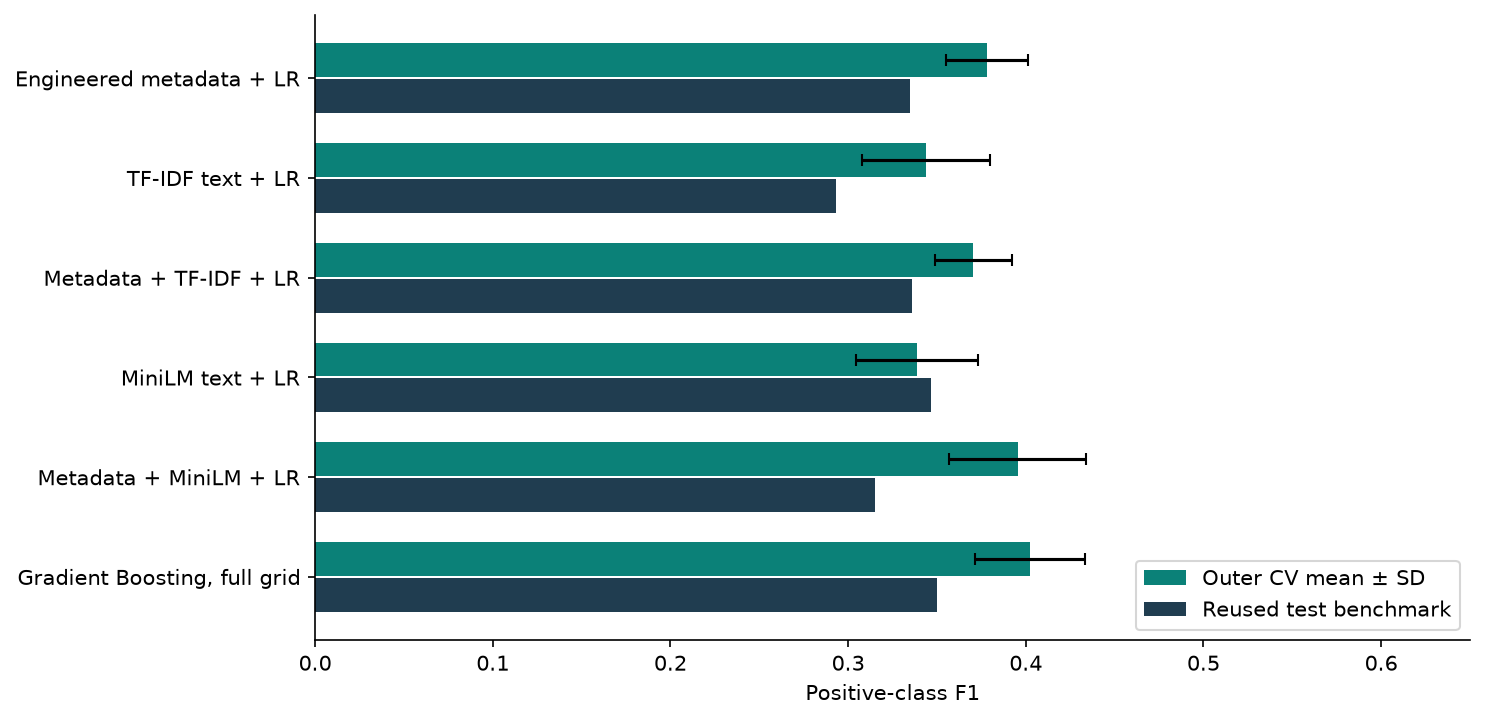

MiniLM added to the same metadata logistic-regression pipeline decreased test F1 by 0.019. The paired 95% bootstrap interval is [-0.055, 0.014]. Training cross-validation selected Gradient Boosting, full grid as the primary model.


,baseline,new,outer_cv_f1_delta,test_f1_delta,low_95,high_95
0,engineered_metadata,tfidf_combined,-0.0079,0.0013,0.0000,0.0046
1,engineered_metadata,lsa_combined,0.0094,-0.0106,-0.0274,0.0000
2,engineered_metadata,minilm_combined,0.0170,-0.0193,-0.0549,0.0136
3,gradient_boosting,tfidf_combined,-0.0320,-0.0142,-0.0596,0.0335
4,gradient_boosting,lsa_combined,-0.0147,-0.0261,-0.0745,0.0219
5,gradient_boosting,minilm_combined,-0.0071,-0.0348,-0.0827,0.0129
6,target_encoded_metadata,target_minilm_combined,-0.0091,0.0095,-0.0204,0.0414


In [5]:
selection = json.loads((OUT / 'selection_before_test.json').read_text())
print('Primary model selected by training CV:', selection['primary'])
comparison = pd.read_csv(OUT / 'model_comparison.csv')
display(comparison[['name', 'cv_f1_mean', 'cv_f1_sd', 'test_f1', 'test_precision', 'test_recall', 'test_roc_auc']].round(4))
display(Image(filename=str(OUT / 'figures/representation_comparison.png')))
print(summary['conclusion'])
display(pd.DataFrame(summary['deltas'])[['baseline', 'new', 'outer_cv_f1_delta', 'test_f1_delta', 'low_95', 'high_95']].round(4))

## 5. Neural-network checkpoint and overfitting

Four MLP architectures are compared with four L2 penalties and four learning rates. Every fit has its own internal stratified validation split. Validation log loss chooses the epoch; F1 evaluates class predictions. The saved model restores the **absolute minimum validation-loss weights**, including improvements smaller than the stopping tolerance.

Interpret the gap: if fitting loss continues to fall while validation loss rises, the model increasingly fits details that do not generalise to the validation examples. Patience allows observation of this trend; the later weights are discarded.

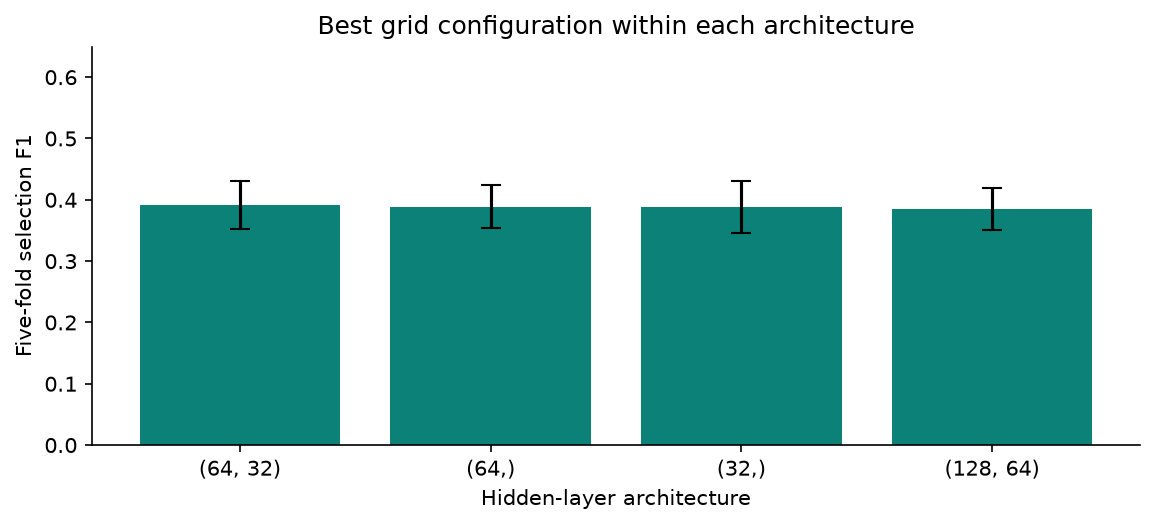

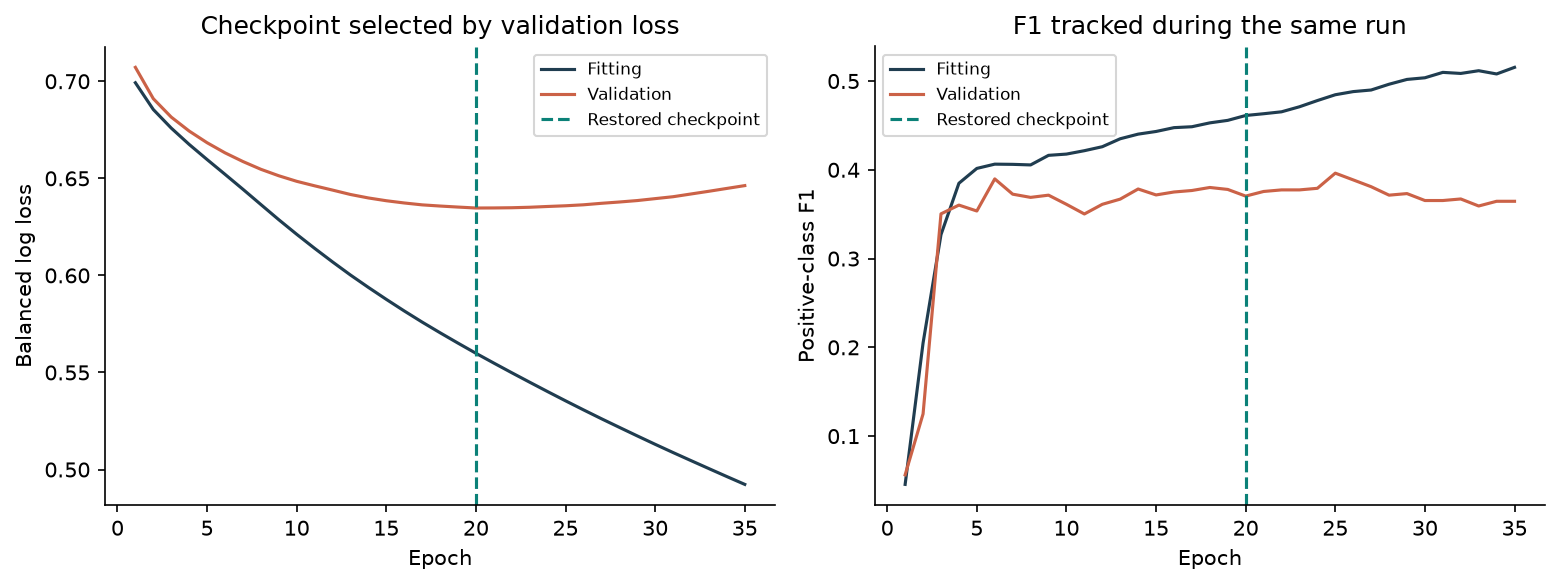

,best_epoch,stopped_epoch,best_validation_loss,gap_at_best,gap_at_stop,parameters
0,20,35,0.63471,0.07483,0.153907,9537


In [6]:
display(Image(filename=str(OUT / 'figures/architecture_comparison.png')))
display(Image(filename=str(OUT / 'figures/mlp_learning.png')))
mlp = summary['mlp']
display(pd.DataFrame([{key: mlp[key] for key in [
    'best_epoch', 'stopped_epoch', 'best_validation_loss', 'gap_at_best', 'gap_at_stop', 'parameters'
]}]))
history = pd.read_csv(OUT / 'searches/mlp/learning_history.csv')
assert int(history.loc[history.validation_balanced_log_loss.idxmin(), 'epoch']) == mlp['best_epoch']

## 6. Explain specific errors

An error list alone does not explain a model. The reviewed cases below connect observed metadata, training-group statistics and measured model sensitivity to each mistake. Replacing a feature or removing a sentence probes the fitted model. It cannot prove the cause of the audience rating.

Nip/Tuck / 7.8
The metadata logistic model makes a false positive at score 0.575. Replacing premiere year 2003 with the training median 2010 reduces that score to 0.367; replacing FX with the modal ABC reduces it to 0.469. This indicates reliance on older-premiere and channel associations. MiniLM combination corrects the class at 0.466. Removing the sentence about the surgeons sharing a relationship raises the combined score to 0.509 and restores the false positive. The measured text sensitivity identifies information beyond the metadata that changes this decision. Gradient Boosting already predicts the correct class at 0.476, so this repair of the logistic baseline does not establish an advantage over the strongest structured model.

The Vampire Diaries / 7.9
The observed rating is 0.1 below the target boundary. Metadata logistic regression correctly remains below the threshold at 0.484. MiniLM combination raises the score to 0.518, introducing a false positive. Removing the opening v

,family,TN,FP,FN,TP
0,random_forest,257,130,41,40
1,gradient_boosting,256,131,36,45
2,mlp,251,136,39,42
3,original_metadata,249,138,38,43
4,engineered_metadata,259,128,39,42
5,tfidf_text,270,117,47,34
6,tfidf_combined,260,127,39,42
7,lsa_text,233,154,37,44
8,lsa_combined,256,131,40,41
9,minilm_text,239,148,33,48


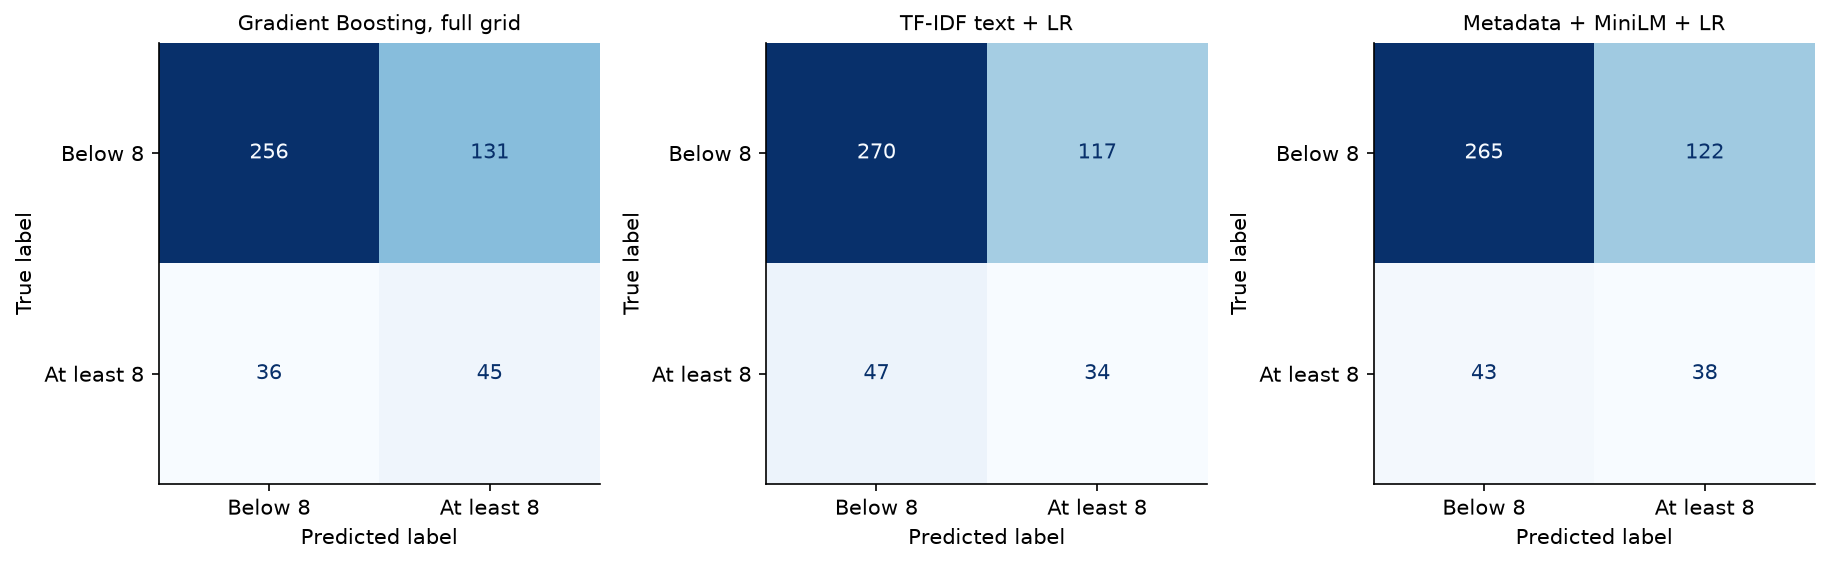

In [7]:
findings = json.loads((OUT / 'reviewed_findings.json').read_text())
for case in findings['cases']:
    print(case['name'])
    print(case['text'])
    print()
print(findings['additional_error_note'])
display(pd.read_csv(OUT / 'error_counts.csv'))
display(Image(filename=str(OUT / 'figures/confusion_matrices.png')))

## 7. Actually load a saved model and predict

Training produces a `.joblib` file containing the fitted transformations and classifier. Loading it reconstructs those learned objects. Calling `.predict()` transforms new feature values with the saved preprocessing and runs the learned decision rule. It does **not** retrain the model.

The example below is a real test-series input. Its observed rating is displayed only to assess the prediction. `FEATURES + ['plot_summary']` is the explicit input whitelist.

In [8]:
family = summary['primary']
model = joblib.load(ROOT / 'models/final' / f'{family}.joblib')
example = test.loc[test.show_id.eq(2)].iloc[[0]]
display(example[['name', 'rating'] + FEATURES])
prediction = model.predict(example[FEATURES + ['plot_summary']])
print('Model:', family)
print('Predicted class:', int(prediction[0]), '(1 means rating >= 8)')
all_predictions = model.predict(test[FEATURES + ['plot_summary']])
reported = comparison.set_index('family').loc[family, 'test_f1']
assert np.isclose(f1_score(test.high_rated, all_predictions), reported, atol=1e-12)
print('Reloaded-model test F1:', f1_score(test.high_rated, all_predictions))
print('Confusion matrix [true rows, predicted columns]:')
print(confusion_matrix(test.high_rated, all_predictions))

,name,rating,premiere_year,runtime_minutes,network,web_channel,broadcast_country,distribution,genres
0,Person of Interest,8.8,2011.0,60.0,CBS,None,US,Broadcast,"[""Action"", ""Crime"", ""Science-Fiction""]"


Model: gradient_boosting
Predicted class: 1 (1 means rating >= 8)
Reloaded-model test F1: 0.35019455252918286
Confusion matrix [true rows, predicted columns]:
[[256 131]
 [ 36  45]]


## 8. A genuinely new input through the app

`python app.py` starts a local server at `http://127.0.0.1:8765`. The browser sends feature values to the Flask route. The route builds an input row, loads the three saved models and returns their outputs. Changing the form changes the input; pressing Predict does not start training.

The following cell calls that same route with a fictional series. Its true rating is unknown. It also demonstrates missing-text fallback and an actionable invalid-input response.

In [9]:
sys.path.insert(0, str(ROOT))
from app import create_app
client = create_app().test_client()
new_series = {
    'premiere_year': 2026, 'runtime_minutes': 45,
    'network': 'Unknown', 'web_channel': 'Netflix',
    'broadcast_country': 'US', 'distribution': 'Streaming',
    'genres': ['Drama', 'Mystery'],
    'plot_summary': 'An astronomer investigates a signal with a retired engineer.'
}
response = client.post('/api/predict', json=new_series)
assert response.status_code == 200, response.json
display(pd.DataFrame(response.json['models']))
missing = client.post('/api/predict', json={**new_series, 'plot_summary': '', 'runtime_minutes': None})
assert missing.status_code == 200
print('Without a synopsis, the available primary role is:', missing.json['primary_role'])
invalid = client.post('/api/predict', json={**new_series, 'runtime_minutes': -10})
assert invalid.status_code == 400
print('Invalid input:', invalid.json['error'])

,role,family,available,predicted,score,score_kind,threshold,label
0,metadata,gradient_boosting,True,0,0.175558,model score,0.5,Rating below 8
1,text,tfidf_text,True,0,0.499958,model score,0.5,Rating below 8
2,combined,minilm_combined,True,0,0.245060,model score,0.5,Rating below 8


Without a synopsis, the available primary role is: metadata
Invalid input: Runtime minutes must be between 1 and 600.


## 9. What the evidence supports

For this cohort, split and training protocol, adding frozen MiniLM synopsis features does not demonstrate a reliable F1 improvement over metadata. Controlled test F1 falls from 0.335 to 0.315, and the paired interval includes zero. Text changes individual decisions in both useful and harmful directions. The training-CV-selected Gradient Boosting remains the primary saved model at test F1 0.350. The finding concerns the tested representations and reused benchmark; a new temporal or franchise-grouped evaluation is needed before extending the claim to unseen series.

The random split can place related franchises in both partitions. The benchmark was reused across course stages. The snapshot excludes unrated series, has no vote counts and covers only rated English scripted series. Synopsis semantics can describe genre without revealing execution quality. A fresh franchise-grouped or temporal evaluation would test a stronger claim about unseen series.

### Reproduce and inspect

```bash
python code/run_final.py --verify-only
python -m unittest discover -s tests -v
python app.py
# Expensive: rerun every saved full grid
python code/run_final.py --fresh --workers 4
```

The report contains parameter ranges, positions of selected settings, specific error explanations, feedback responses and required tool disclosure. Full grids are in `results/final/searches/`; per-series predictions and paired intervals are in `results/final/`.